In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import matplotlib.pyplot as plt

#Konfigurasi Path File

In [ ]:
PATH_SPOTIFY    = "/content/Assignment - spotify_campaign_data.xlsx - spotify_campaign_data.csv"
PATH_MONITORING = "/content/Assignment - AB Test - Post Implement.xlsx - Sheet1.csv"

# Warna tema Spotify untuk chart
COLOR_CONTROL = "#8896A6"
COLOR_TARGET  = "#1DB954"
COLOR_DARK    = "#191414"

# Load & Clean Data A/B Test (spotify_campaign_data)

In [ ]:
df = pd.read_csv(PATH_SPOTIFY)

In [ ]:
# Engagement & Duration Played tersimpan sebagai string dengan koma desimal
# (format lokal), perlu dikonversi ke float dengan titik desimal.
df["Engagement"] = df["Engagement"].str.replace(",", ".").astype(float)
df["Duration Played"] = df["Duration Played"].str.replace(",", ".").astype(float)

In [ ]:
# Buat kolom biner untuk uji proporsi
df["Payment_bin"] = (df["Payment"] == "Yes").astype(int)
df["Premium_bin"] = (df["Subscription"] == "Premium").astype(int)

print("Jumlah baris:", len(df))
print(df["Group"].value_counts())
print(df.head())

Jumlah baris: 100000
Group
Control    50000
Target     50000
Name: count, dtype: int64
     Group  Engagement  Duration Played Payment Subscription  Payment_bin  \
0  Control    0.649671       122.946184     Yes      Premium            1   
1  Control    0.586174       118.076753     Yes         Free            1   
2  Control    0.664769       148.553723     Yes      Premium            1   
3  Control    0.752303       165.984934      No      Premium            0   
4  Control    0.576585       140.605408     Yes         Free            1   

   Premium_bin  
0            1  
1            0  
2            1  
3            1  
4            0  


#Statistik Deskriptif per Group

In [ ]:
summary = df.groupby("Group").agg(
    n=("Engagement", "size"),
    Engagement_mean=("Engagement", "mean"),
    Engagement_std=("Engagement", "std"),
    Duration_mean=("Duration Played", "mean"),
    Duration_std=("Duration Played", "std"),
    Payment_rate=("Payment_bin", "mean"),
    Premium_rate=("Premium_bin", "mean"),
)
print("\n=== Statistik Deskriptif ===")
print(summary)

c = df[df["Group"] == "Control"]
t = df[df["Group"] == "Target"]


=== Statistik Deskriptif ===
             n  Engagement_mean  Engagement_std  Duration_mean  Duration_std  \
Group                                                                          
Control  50000         0.599958        0.100017     120.070639     30.049488   
Target   50000         0.799726        0.100046     159.912912     30.018948   

         Payment_rate  Premium_rate  
Group                                
Control       0.69688       0.59742  
Target        0.79814       0.80250  


#Uji Hipotesis

In [ ]:
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

def cohend(a, b):
    """Cohen's d untuk dua sampel independen."""
    na, nb = len(a), len(b)
    pooled_std = np.sqrt(((na - 1) * a.std(ddof=1) ** 2 + (nb - 1) * b.std(ddof=1) ** 2) / (na + nb - 2))
    return (a.mean() - b.mean()) / pooled_std

def mean_diff_ci(a, b, alpha=0.05):
    """CI 95% untuk selisih dua rata-rata (asumsi varians tak sama / Welch)."""
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return diff, diff - z * se, diff + z * se

print("\n=== 3.1 Engagement (Welch t-test) ===")
tstat, p = stats.ttest_ind(t["Engagement"], c["Engagement"], equal_var=False)
diff, lo, hi = mean_diff_ci(t["Engagement"], c["Engagement"])
print(f"t = {tstat:.3f}, p = {p:.4g}")
print(f"Selisih rata-rata = {diff:.4f}  (95% CI: {lo:.4f} s.d. {hi:.4f})")
print(f"Cohen's d = {cohend(t['Engagement'], c['Engagement']):.3f}")

print("\n=== 3.2 Duration Played (Welch t-test) ===")
tstat2, p2 = stats.ttest_ind(t["Duration Played"], c["Duration Played"], equal_var=False)
diff2, lo2, hi2 = mean_diff_ci(t["Duration Played"], c["Duration Played"])
print(f"t = {tstat2:.3f}, p = {p2:.4g}")
print(f"Selisih rata-rata = {diff2:.2f} menit (95% CI: {lo2:.2f} s.d. {hi2:.2f})")
print(f"Cohen's d = {cohend(t['Duration Played'], c['Duration Played']):.3f}")

print("\n=== 3.3 Payment Rate (two-proportion z-test) ===")
count = np.array([t["Payment_bin"].sum(), c["Payment_bin"].sum()])
nobs = np.array([len(t), len(c)])
zstat, pval = proportions_ztest(count, nobs)
ci_t = proportion_confint(count[0], nobs[0], method="wilson")
ci_c = proportion_confint(count[1], nobs[1], method="wilson")
print(f"z = {zstat:.3f}, p = {pval:.4g}")
print(f"Target: {count[0]/nobs[0]:.4f}  (95% CI {ci_t[0]:.4f}-{ci_t[1]:.4f})")
print(f"Control: {count[1]/nobs[1]:.4f}  (95% CI {ci_c[0]:.4f}-{ci_c[1]:.4f})")

print("\n=== 3.4 Premium Rate (two-proportion z-test) ===")
count2 = np.array([t["Premium_bin"].sum(), c["Premium_bin"].sum()])
zstat2, pval2 = proportions_ztest(count2, nobs)
ci_t2 = proportion_confint(count2[0], nobs[0], method="wilson")
ci_c2 = proportion_confint(count2[1], nobs[1], method="wilson")
print(f"z = {zstat2:.3f}, p = {pval2:.4g}")
print(f"Target: {count2[0]/nobs[0]:.4f}  (95% CI {ci_t2[0]:.4f}-{ci_t2[1]:.4f})")
print(f"Control: {count2[1]/nobs[1]:.4f}  (95% CI {ci_c2[0]:.4f}-{ci_c2[1]:.4f})")


=== 3.1 Engagement (Welch t-test) ===
t = 315.762, p = 0
Selisih rata-rata = 0.1998  (95% CI: 0.1985 s.d. 0.2010)
Cohen's d = 1.997

=== 3.2 Duration Played (Welch t-test) ===
t = 209.748, p = 0
Selisih rata-rata = 39.84 menit (95% CI: 39.47 s.d. 40.21)
Cohen's d = 1.327

=== 3.3 Payment Rate (two-proportion z-test) ===
z = 36.853, p = 2.582e-297
Target: 0.7981  (95% CI 0.7946-0.8016)
Control: 0.6969  (95% CI 0.6928-0.7009)

=== 3.4 Premium Rate (two-proportion z-test) ===
z = 70.757, p = 0
Target: 0.8025  (95% CI 0.7990-0.8060)
Control: 0.5974  (95% CI 0.5931-0.6017)


In [ ]:
# Cek confounding: apakah Payment Rate konsisten di semua tier Subscription?

print("\n=== Cek Confounding: Payment Rate per Group x Subscription ===")
print(df.groupby(["Group", "Subscription"])["Payment_bin"].mean())



=== Cek Confounding: Payment Rate per Group x Subscription ===
Group    Subscription
Control  Free            0.699290
         Premium         0.695256
Target   Free            0.799190
         Premium         0.797882
Name: Payment_bin, dtype: float64


#Visualisasi Eksperimen A/B Testing

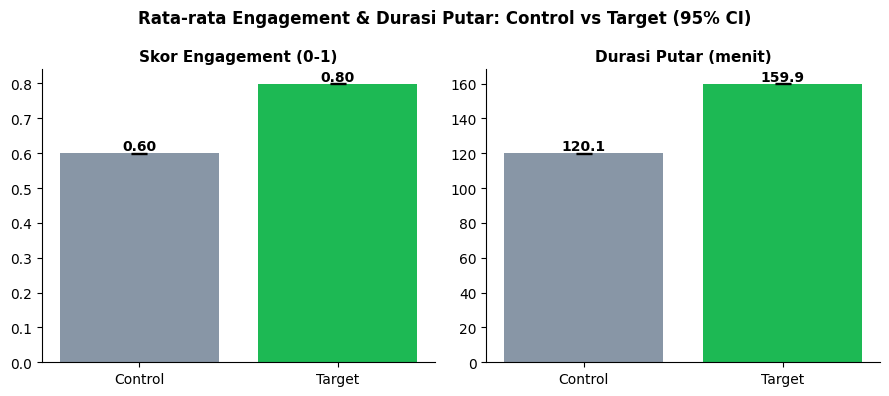

In [ ]:
# --- Chart 1: rata-rata Engagement & Duration Played ---

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for i, (col, ylab) in enumerate([("Engagement", "Skor Engagement (0-1)"),
                                  ("Duration Played", "Durasi Putar (menit)")]):
    means = df.groupby("Group")[col].mean().reindex(["Control", "Target"])
    sems = df.groupby("Group")[col].sem().reindex(["Control", "Target"])
    bars = axes[i].bar(means.index, means.values, yerr=1.96 * sems.values, capsize=6,
                        color=[COLOR_CONTROL, COLOR_TARGET])
    axes[i].set_title(ylab, fontsize=11, fontweight="bold")
    for b, v in zip(bars, means.values):
        axes[i].text(b.get_x() + b.get_width() / 2, v,
                      f"{v:.2f}" if col == "Engagement" else f"{v:.1f}",
                      ha="center", va="bottom", fontsize=10, fontweight="bold")
    axes[i].spines[["top", "right"]].set_visible(False)
plt.suptitle("Rata-rata Engagement & Durasi Putar: Control vs Target (95% CI)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("chart1_means.png", dpi=160)
plt.show()

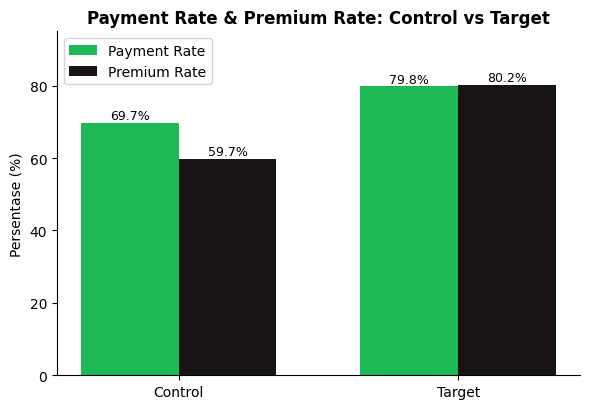

In [ ]:
# --- Chart 2: Payment Rate & Premium Rate ---

fig, ax = plt.subplots(figsize=(6, 4.2))
pay = df.groupby("Group")["Payment_bin"].mean().reindex(["Control", "Target"]) * 100
prem = df.groupby("Group")["Premium_bin"].mean().reindex(["Control", "Target"]) * 100
x = np.arange(2)
w = 0.35
b1 = ax.bar(x - w / 2, pay.values, w, label="Payment Rate", color=COLOR_TARGET)
b2 = ax.bar(x + w / 2, prem.values, w, label="Premium Rate", color=COLOR_DARK)
ax.set_xticks(x)
ax.set_xticklabels(["Control", "Target"])
ax.set_ylabel("Persentase (%)")
ax.set_title("Payment Rate & Premium Rate: Control vs Target", fontsize=12, fontweight="bold")
for bars in [b1, b2]:
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1,
                 f"{b.get_height():.1f}%", ha="center", fontsize=9)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, 95)
plt.tight_layout()
plt.savefig("chart2_rates.png", dpi=160)
plt.show()

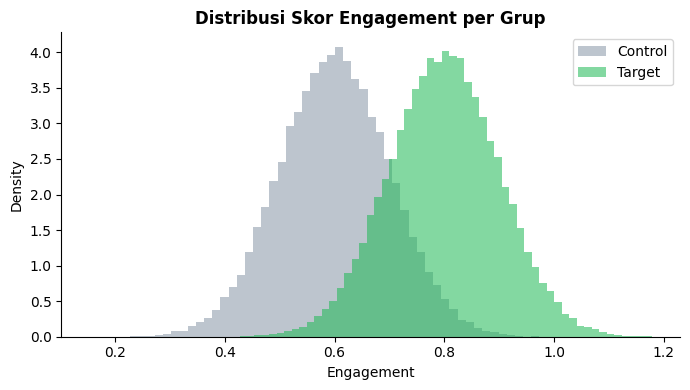

In [ ]:
# --- Chart 3: distribusi Engagement ---

fig, ax = plt.subplots(figsize=(7, 4))
for g, color in [("Control", COLOR_CONTROL), ("Target", COLOR_TARGET)]:
    sub = df[df["Group"] == g]["Engagement"]
    ax.hist(sub, bins=60, alpha=0.55, label=g, color=color, density=True)
ax.set_title("Distribusi Skor Engagement per Grup", fontsize=12, fontweight="bold")
ax.set_xlabel("Engagement")
ax.set_ylabel("Density")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("chart3_dist.png", dpi=160)
plt.show()

#Monitoring Pasca-Implementasi (AB_Test_Post_Implement)

In [ ]:
mon = pd.read_csv(PATH_MONITORING)
mon["Date"] = pd.to_datetime(mon["Date"], format="%d-%b-%y")
mon = mon.sort_values("Date").reset_index(drop=True)
print("\n=== Data Monitoring ===")
print(mon)


=== Data Monitoring ===
         Date  Total Users
0  2026-03-01        19304
1  2026-03-02        16799
2  2026-03-03        13986
3  2026-03-04        15981
4  2026-03-05        18390
5  2026-03-06        17169
6  2026-03-07        11660
7  2026-03-08        21853
8  2026-03-09        20960
9  2026-03-10        22583
10 2026-03-11        29803
11 2026-03-12        25468
12 2026-03-13        25814
13 2026-03-14        26207
14 2026-03-15        24446


In [ ]:
# Bagi 15 hari menjadi Minggu 1 (hari 1-7) dan Minggu 2 (hari 8-14)

week1_mean = mon.iloc[0:7]["Total Users"].mean()
week2_mean = mon.iloc[7:14]["Total Users"].mean()
pct_change = (week2_mean - week1_mean) / week1_mean * 100
print(f"\nRata-rata Minggu 1 (1-7 Mar): {week1_mean:,.0f}")
print(f"Rata-rata Minggu 2 (8-14 Mar): {week2_mean:,.0f}")
print(f"Perubahan: {pct_change:+.1f}%")


Rata-rata Minggu 1 (1-7 Mar): 16,184
Rata-rata Minggu 2 (8-14 Mar): 24,670
Perubahan: +52.4%


In [ ]:
# Uji tren linear (regresi sederhana terhadap waktu)

x = np.arange(len(mon))
slope, intercept, r_value, p_value, se = stats.linregress(x, mon["Total Users"])
print(f"\nTren linear: slope = {slope:.1f} users/hari, R^2 = {r_value**2:.3f}, p = {p_value:.4g}")


Tren linear: slope = 871.1 users/hari, R^2 = 0.582, p = 0.0009408


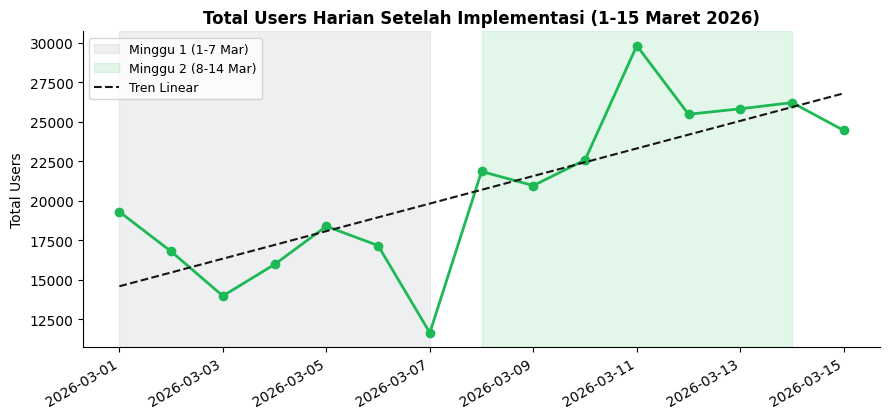

In [ ]:
# --- Chart 4: tren Total Users ---

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(mon["Date"], mon["Total Users"], marker="o", color=COLOR_TARGET, linewidth=2)
ax.axvspan(mon["Date"].iloc[0], mon["Date"].iloc[6], color=COLOR_CONTROL, alpha=0.15, label="Minggu 1 (1-7 Mar)")
ax.axvspan(mon["Date"].iloc[7], mon["Date"].iloc[13], color=COLOR_TARGET, alpha=0.12, label="Minggu 2 (8-14 Mar)")
trend = intercept + slope * x
ax.plot(mon["Date"], trend, "--", color=COLOR_DARK, linewidth=1.5, label="Tren Linear")
ax.set_title("Total Users Harian Setelah Implementasi (1-15 Maret 2026)", fontsize=12, fontweight="bold")
ax.set_ylabel("Total Users")
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("chart4_monitoring.png", dpi=160)
plt.show()